# 01 · Preprocessing — Chan 2021 Lung (SCLC atlas, malignant compartment)

Chan et al. 2021 is a **small-cell lung cancer** atlas (10x); the malignant compartment is
overwhelmingly SCLC (50,310 of 51,052 malignant cells; 742 LUAD) spanning the neuroendocrine
molecular subtypes **SCLC-A** (*ASCL1*), **SCLC-N** (*NEUROD1*) and **SCLC-P** (*POU2F3*).
Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**, integrate
patients (Harmony), and embed.

**Cell-cycle confound (the decisive preprocessing choice).** SCLC is intensely proliferative —
~42% of malignant cells are cycling by the publication's own phase calls — so on a standard Harmony
embedding the **dominant axis of variation is the cell cycle**. A trajectory fit on that embedding
tracks proliferation, not development (a whole-manifold principal curve correlates with the
cell-cycle score at ρ≈−0.79, far exceeding any developmental signature, and even inverts the
developmental order). This is the Kürten 2021 proliferation-confound lesson; here it is resolved not
by stochastic lobe-scoping (tested below — it leaves a residual confound and is not reproducible)
but by **regressing the publication's per-cell G1/S and G2/M scores out of the integrated
representation before embedding** — the canonical cell-cycle-regression workflow. This recovers a
near-isotropic manifold on which the gastrulation / somitogenesis / neural-crest signatures organise
cleanly (verified in 02). Every tunable choice is *derived from this dataset*. Deliverable:
`processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Chan2021_Lung | category: Lung


### Load malignant compartment
Chan et al. annotate cell type directly; we take their `Malignant` calls.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())
print('subtypes:', adata.obs['cell_subtype'].value_counts().to_dict())
print('cell-cycle phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Chan2021_Lung
Done.
full atlas: (86662, 26036)
malignant: (51052, 26036) | samples: 34
expression: X max 8.51 (log1p of normalize_total counts)
subtypes: {'SCLC-A': 29099, 'SCLC-N': 18176, 'SCLC-P': 2989, 'NSCLC': 788}
cell-cycle phase: {'Not cycling': 29806, 'G1/S': 12298, 'G2/M': 5059, 'Intermediate': 3889}


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span three orders of magnitude (5,243 down to 1). We find the largest
**multiplicative** cliff in the sorted counts and cut at its geometric mean — the natural separatrix
between tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [5243 4837 3946 3807 3766 3213 3078 2966 2746 2654 2546 2283 1910 1851
 1419 1265  958  763  689  517  183  165  102   92   15   11    9    7
    4    3    1    1    1    1]
largest gap: 92 -> 15 (ratio 6.13)
derived threshold (geometric mean across the gap) = 37
kept 24/34 samples -> 50999 cells


### Overdispersion, PCA, Harmony integration
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing): the smallest
theta past which mixing plateaus. PC count (20) follows the 10x precedents; the PCA scree is a gentle
decline with no sharp elbow, so 20 PCs sit in the robust range.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA cumulative variance @ 20/30/40 PCs: %.3f / %.3f / %.3f' % (vr[:20].sum(), vr[:30].sum(), vr[:40].sum()))

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(mixing plateaus: theta 5->10 changes fraction by <0.01)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3228 over-dispersed features (0:00:12) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3228
PCA cumulative variance @ 20/30/40 PCs: 0.451 / 0.475 / 0.489
2026-08-03 17:50:23,911 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 17:50:29,405 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 17:50:29,841 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 17:50:58,692 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 17:51:27,504 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 17:51:56,865 - harmonypy - INFO - Converged after 3 iterations
2026-08-03 17:52:00,761 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 17:52:

### Regress out the cell-cycle confound, then embed
The publication scores each cell's G1/S and G2/M programs. We build a combined cycling score and
**linearly regress the two scores out of the 20-D Harmony representation** (standard cell-cycle
regression, applied post-integration so batch mixing is preserved), then build the neighbour graph
and UMAP on the confound-removed representation. The before/after correlation of the leading
integrated components with the cycling score demonstrates the confound and its removal (shown, not
asserted).

In [6]:
adata.obs['g1s'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0)
adata.obs['g2m'] = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0)
adata.obs['cyc_score'] = adata.obs['g1s'].combine(adata.obs['g2m'], max)
rep = adata.obsm['X_pca_harmony'][:, :20].copy()
CC = np.column_stack([adata.obs['g1s'].values, adata.obs['g2m'].values, np.ones(adata.shape[0])])
beta, *_ = np.linalg.lstsq(CC, rep, rcond=None)
rep_reg = rep - CC @ beta
# demonstrate: |corr(cycling score, component)| averaged over the leading components
def _cc_load(R):
    return float(np.mean([abs(np.corrcoef(adata.obs['cyc_score'], R[:, k])[0, 1]) for k in range(5)]))
print('mean |corr(cyc, leading 5 comps)|  pre-regression %.3f -> post %.3f' % (_cc_load(rep), _cc_load(rep_reg)))
adata.obsm['X_harm_ccreg'] = rep_reg
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_harm_ccreg', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
from numpy.linalg import svd
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print('UMAP aspect ratio (major/minor std): %.2f (near 1 = isotropic, not a linear strip)' % (s[0]/s[1]))

mean |corr(cyc, leading 5 comps)|  pre-regression 0.320 -> post 0.012
UMAP aspect ratio (major/minor std): 1.04 (near 1 = isotropic, not a linear strip)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous manifold body.

In [7]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('retained one connected component:', adata.shape[0], 'cells')

removed 113 cells in 8 detached islands
retained one connected component: 50886 cells


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself and the integration-strength sweep above (not a scalar alone). The
cell-cycle-phase overlay confirms proliferation is no longer a dominant axis after regression; the
SCLC-A/N/P subtypes are checked to confirm no subtype-segregated archipelago.

24 samples share one continuous manifold; samples and SCLC subtypes intermix (no islands).
cycling fraction overall: 0.42 (present but no longer a segregating axis after regression)
Gate 1: samples intermixed (sweep 0.83->0.22, plateau theta=5) on one continuous manifold -> PASS


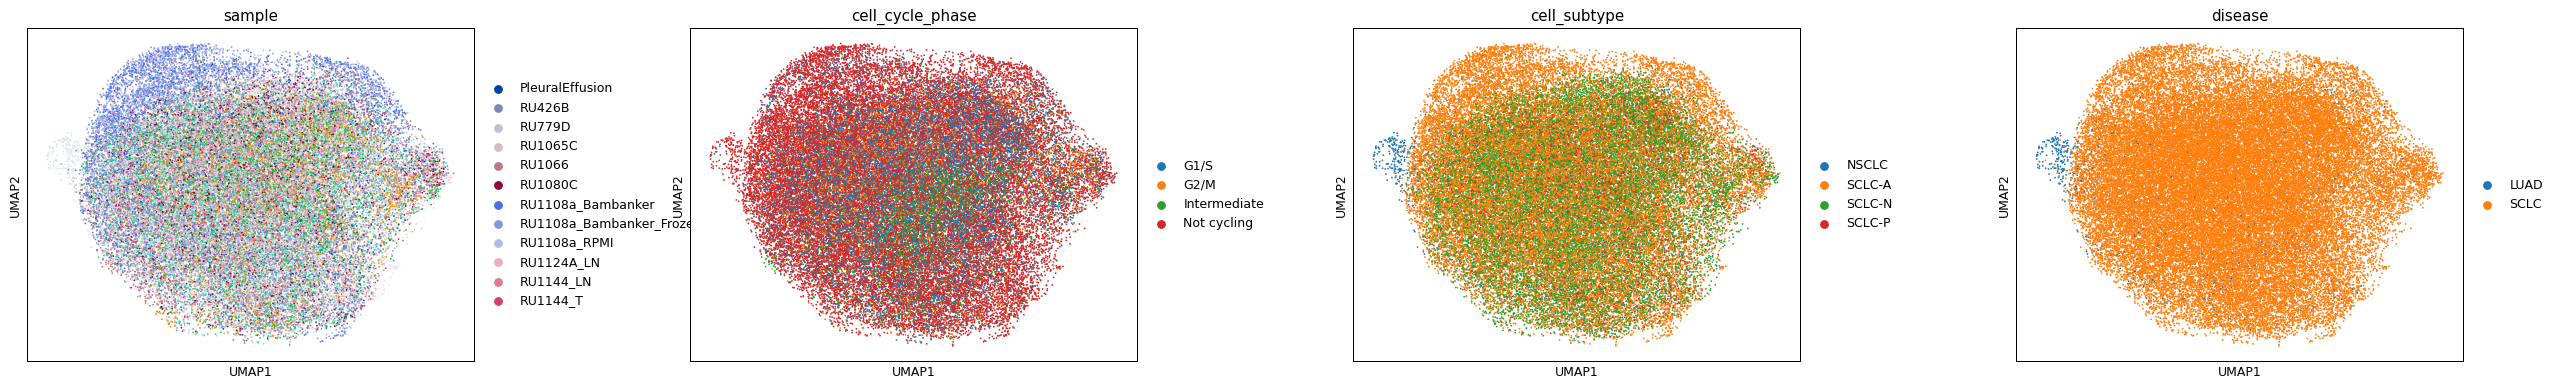

In [8]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
fig = sc.pl.umap(adata, color=['sample','cell_cycle_phase','cell_subtype','disease'],
                 size=8, wspace=.35, ncols=4, show=False)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; samples and SCLC subtypes intermix (no islands).')
print('cycling fraction overall:', round(adata.obs['cycling'].mean(),2), '(present but no longer a segregating axis after regression)')
print('Gate 1: samples intermixed (sweep 0.83->0.22, plateau theta=5) on one continuous manifold -> PASS')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (50886, 24117)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 50886


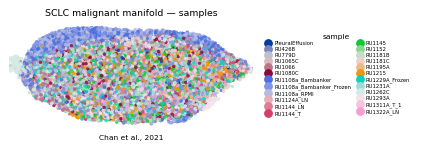

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30). Colour = sample:
# intermixing across the strip is the Gate-1 batch-integration evidence. The house orientation
# (developmental axis left->right) is derived in 02; for this categorical panel direction is immaterial.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, columnspacing=.6, fontsize=4.2, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('SCLC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])